# Credit Default Prediction and Model Explainability

This project aims to predict the probability of credit card default using customers' historical payment information. A Random Forest classification model is trained on the UCI Credit Card dataset and evaluated using ROC-AUC, Precision, Recall, F1, and PR-AUC. SHAP is also used for model explainability, and basic fairness metrics are examined across demographic groups.

> **Not:** This project is intended for academic and portfolio purposes. In a real credit decision system, model predictions should not be used as the sole decision-making factor; legal, ethical, and organizational requirements should also be considered.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve
)


In [2]:
from pathlib import Path

DATA_PATH = Path("data") / "UCI_Credit_Card.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

Target variable distribution:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Proportional distribution:
default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


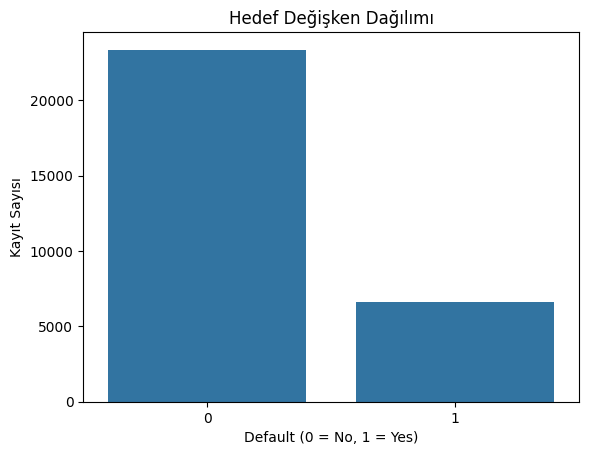

In [4]:
target = "default.payment.next.month"

print("Target variable distribution:")
print(df[target].value_counts())
print("\nProportional distribution:")
print(df[target].value_counts(normalize=True).round(4))

sns.countplot(data=df, x=target)
plt.title("Hedef Değişken Dağılımı")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Kayıt Sayısı")
plt.show()


## Data Preparation

`ID` is excluded because it is only a record identifier. Random Forest does not require feature scaling, so `StandardScaler` is not used. The key methodological improvement is splitting the dataset into training and test sets before model-related preprocessing, helping prevent test data from leaking into the training process.


In [5]:
X = df.drop(columns=[target, "ID"])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (21000, 23)
Test set: (9000, 23)


## Baseline Model

A simple baseline that always predicts the majority class is used to provide a reference point and assess whether the Random Forest provides meaningful improvement.


In [6]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline balanced accuracy:", round(balanced_accuracy_score(y_test, baseline_pred), 4))


Baseline accuracy: 0.7788
Baseline balanced accuracy: 0.5


## Random Forest Model


In [7]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]


In [8]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "PR-AUC": average_precision_score(y_test, y_proba),
}

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))


Accuracy: 0.8119
Balanced Accuracy: 0.6511
Precision: 0.6300
Recall: 0.3626
F1: 0.4603
ROC-AUC: 0.7570
PR-AUC: 0.5238

Classification Report:
              precision    recall  f1-score   support

           0      0.838     0.940     0.886      7009
           1      0.630     0.363     0.460      1991

    accuracy                          0.812      9000
   macro avg      0.734     0.651     0.673      9000
weighted avg      0.792     0.812     0.792      9000



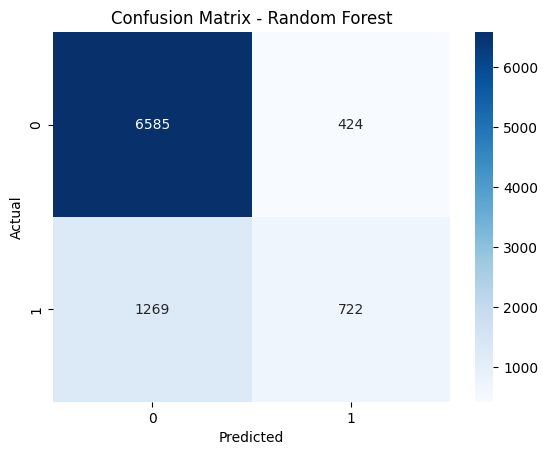

In [9]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


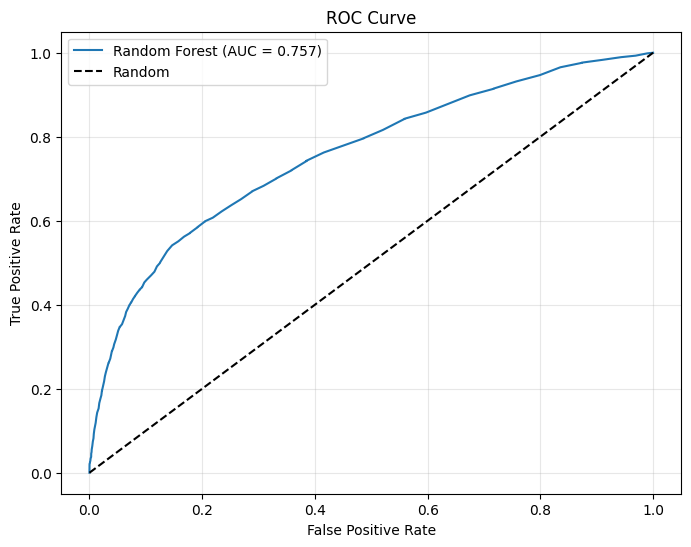

In [10]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


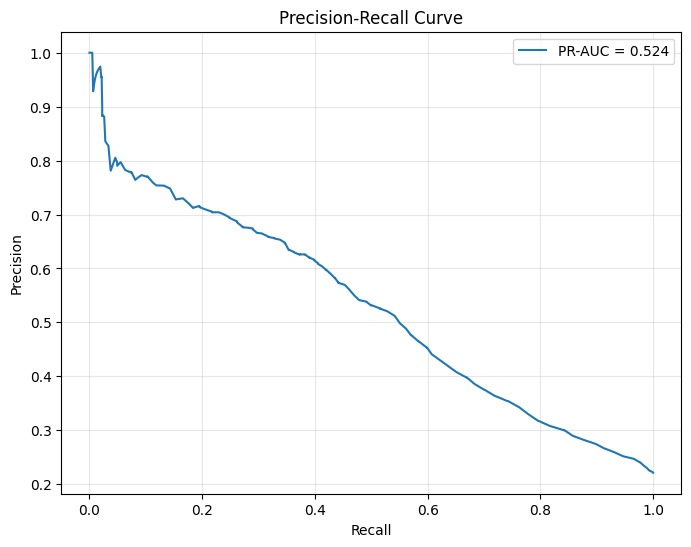

In [11]:
precision, recall, _ = precision_recall_curve(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Feature Importance

Random Forest's built-in feature importance scores show which variables contribute most to the model's predictions. These scores do not imply causality.


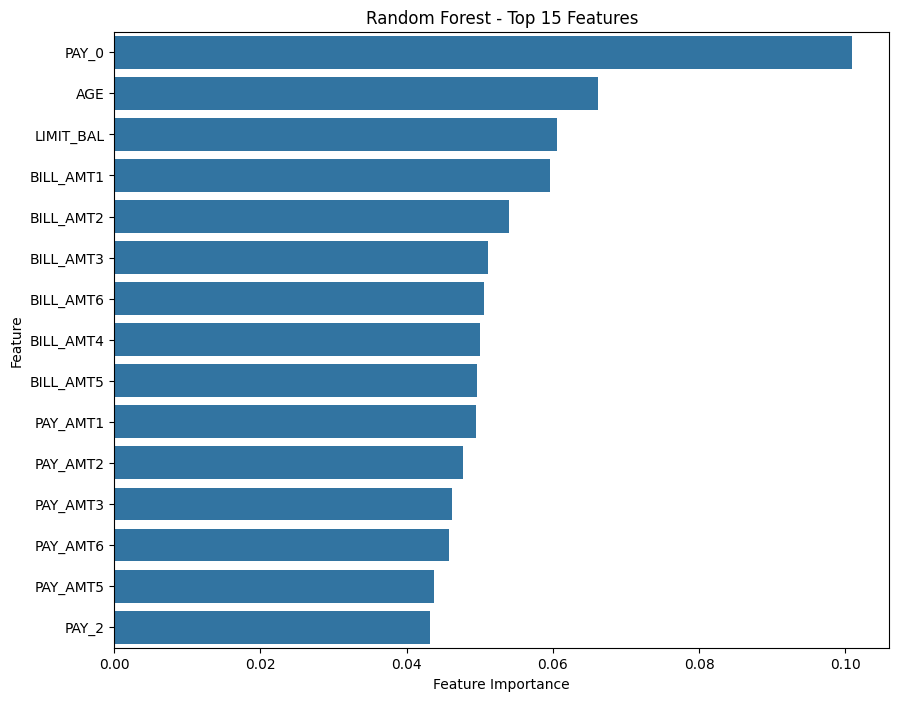

In [12]:
feature_importance = (
    pd.Series(model.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importance.head(15).values, y=feature_importance.head(15).index)
plt.title("Random Forest - Top 15 Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()


## Model Explainability with SHAP

SHAP is used to examine how individual features are associated with individual predictions and overall model behavior. If SHAP is not installed, this section is skipped while the main model remains functional.


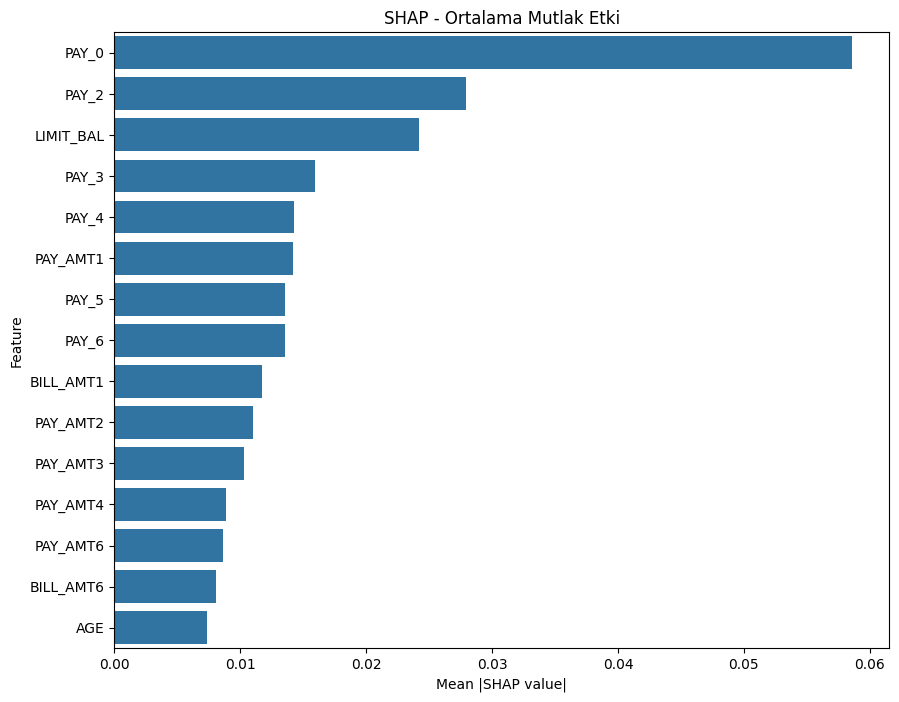

In [13]:
try:
    import shap

    sample = X_test.sample(min(300, len(X_test)), random_state=42)
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(sample)

    # SHAP sürümleri farklı çıktı biçimleri verebildiği için iki yaygın durum ele alınır.
    if isinstance(shap_values, list):
        values = shap_values[1]
    elif getattr(shap_values, "ndim", 0) == 3:
        values = shap_values[:, :, 1]
    else:
        values = shap_values

    shap_importance = (
        pd.Series(np.abs(values).mean(axis=0), index=sample.columns)
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(10, 8))
    sns.barplot(x=shap_importance.values, y=shap_importance.index)
    plt.title("SHAP - Ortalama Mutlak Etki")
    plt.xlabel("Mean |SHAP value|")
    plt.ylabel("Feature")
    plt.show()
except ImportError:
    print("SHAP kurulu değil. `pip install shap` ile kurulabilir.")
except Exception as e:
    print("SHAP analysis could not be completed:", e)


## Demographic Fairness Audit

This section compares basic group-level metrics across the `SEX` variable. Differences in these metrics alone do not prove that a model is fair or unfair; the goal is to identify potential performance differences between groups.


In [14]:
fairness_df = X_test.copy()
fairness_df["y_true"] = y_test
fairness_df["y_pred"] = y_pred

rows = []
for group, group_df in fairness_df.groupby("SEX"):
    tp = ((group_df["y_pred"] == 1) & (group_df["y_true"] == 1)).sum()
    fn = ((group_df["y_pred"] == 0) & (group_df["y_true"] == 1)).sum()
    fp = ((group_df["y_pred"] == 1) & (group_df["y_true"] == 0)).sum()
    tn = ((group_df["y_pred"] == 0) & (group_df["y_true"] == 0)).sum()

    rows.append({
        "SEX": group,
        "N": len(group_df),
        "Positive Prediction Rate": group_df["y_pred"].mean(),
        "TPR / Recall": tp / (tp + fn) if (tp + fn) else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "Precision": tp / (tp + fp) if (tp + fp) else np.nan
    })

fairness_results = pd.DataFrame(rows)
display(fairness_results.round(3))


,SEX,N,Positive Prediction Rate,TPR / Recall,FPR,Precision
0,1,3563,0.133,0.354,0.064,0.634
1,2,5437,0.123,0.369,0.058,0.627


## Results and Discussion

- Model performance is evaluated using more than accuracy, including ROC-AUC, PR-AUC, precision, recall, and F1.
- Because the target classes are imbalanced, recall and PR-AUC are particularly important.
- The `ID` column is excluded from the model.
- The train/test split is performed before model-related preprocessing to reduce the risk of data leakage.
- SHAP analysis provides additional model explainability.
- The fairness section reports basic performance differences across `SEX` groups; these results should not be interpreted as a legal or ethical compliance assessment.
